In [ ]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

## 3.5

### a)

c = [ 1.+0.j   1.-0.j  -0.-0.5j -0.+0.5j  1.+0.j ]
c_g = [1. +0.j  1.5-0.j  0. -0.5j 0. +0.5j 1.5+0.j ]


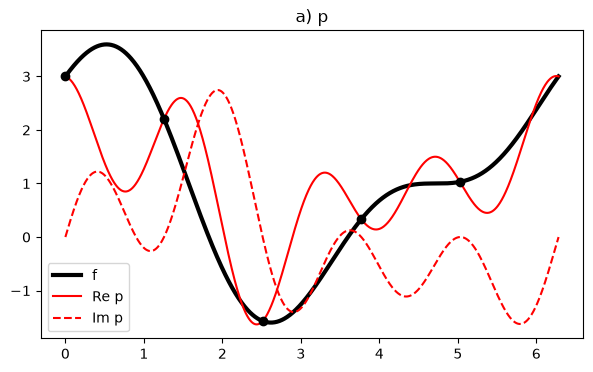

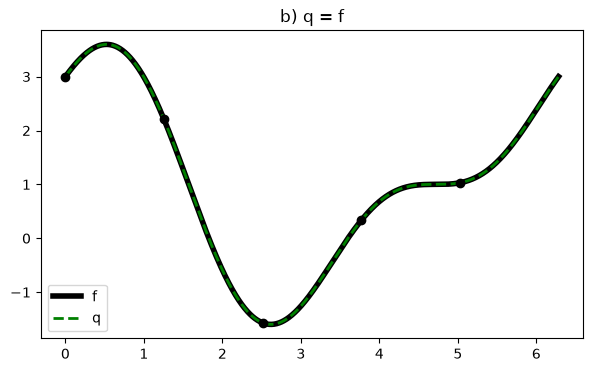

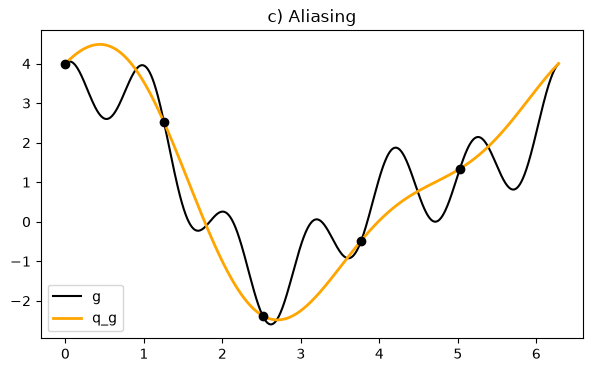

In [4]:
import numpy as np
import matplotlib.pyplot as plt

n = 5
xj = 2*np.pi*np.arange(n)/n
xs = np.linspace(0, 2*np.pi, 1000)
F = lambda t: 1 + 2*np.cos(t) + np.sin(2*t)
G = lambda t: F(t) + np.cos(6*t)

c = np.fft.fft(F(xj))/n
cg = np.fft.fft(G(xj))/n
freqs = [0, 1, 2, -2, -1]
P  = sum(c[k]*np.exp(1j*k*xs) for k in range(n))
Q  = sum(c[k]*np.exp(1j*freqs[k]*xs) for k in range(n))
QG = sum(cg[k]*np.exp(1j*freqs[k]*xs) for k in range(n))
print("c =", np.round(c, 10))
print("c_g =", np.round(cg, 10))

plt.figure(figsize=(7, 4))
plt.plot(xs, F(xs), "k", lw=3, label="f")
plt.plot(xs, P.real, "r", label="Re p")
plt.plot(xs, P.imag, "r--", label="Im p")
plt.plot(xj, F(xj), "ko")
plt.title("a) p"); plt.legend(); plt.show()

plt.figure(figsize=(7, 4))
plt.plot(xs, F(xs), "k", lw=4, label="f")
plt.plot(xs, Q.real, "g--", lw=2, label="q")
plt.plot(xj, F(xj), "ko")
plt.title("b) q = f"); plt.legend(); plt.show()

plt.figure(figsize=(7, 4))
plt.plot(xs, G(xs), "k", label="g")
plt.plot(xs, QG.real, "orange", lw=2, label="q_g")
plt.plot(xj, G(xj), "ko")
plt.title("c) Aliasing"); plt.legend(); plt.show()

### b)

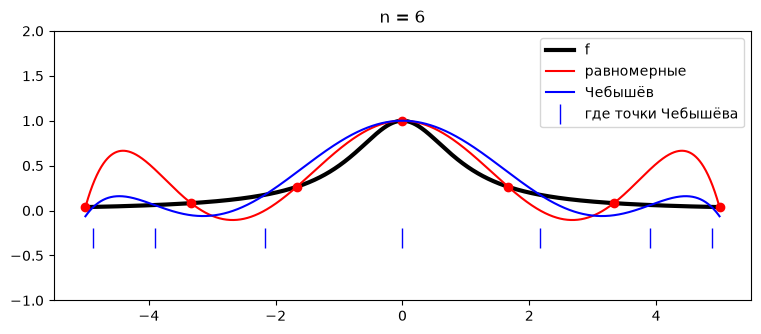

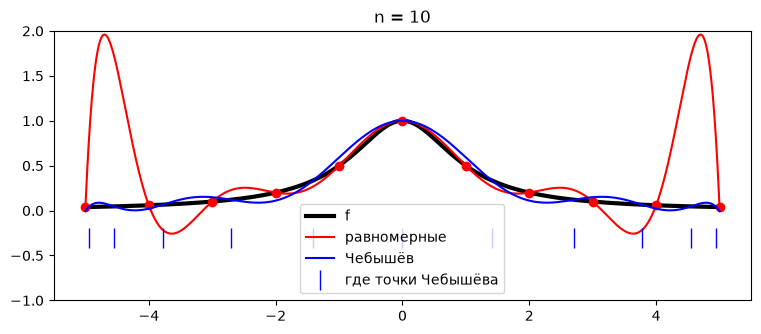

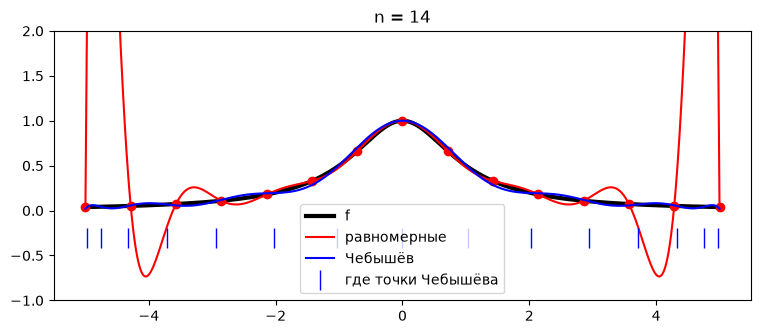

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import BarycentricInterpolator

f = lambda x: 1/(1+x**2)
xs = np.linspace(-5, 5, 2000)

for n in [6, 10, 14]:
    x_unif = np.linspace(-5, 5, n+1)
    x_cheb = 5*np.cos((np.arange(n+1)+0.5)/(n+1)*np.pi)

    plt.figure(figsize=(9, 3.5))
    plt.plot(xs, f(xs), "k", lw=3, label="f")
    plt.plot(xs, BarycentricInterpolator(x_unif, f(x_unif))(xs), "r", label="равномерные")
    plt.plot(x_unif, f(x_unif), "ro")
    plt.plot(xs, BarycentricInterpolator(x_cheb, f(x_cheb))(xs), "b", label="Чебышёв")
    plt.plot(x_cheb, 0*x_cheb - 0.3, "b|", ms=15, label="где точки Чебышёва")
    plt.ylim(-1, 2); plt.title(f"n = {n}"); plt.legend(); plt.show()

### c)